In [2]:
from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd

data_folder = "/data/HER2-IHC-40x/WSI-based-dataset"
 
train_folder = f"{data_folder}/train_data_wsi"
test_folder = f"{data_folder}/test_data_wsi"
VALID_EXTENSIONS = {".png"}


def get_features_dataset(root_path):
    root = Path(root_path)
    records = []

    for subfolder in root.iterdir():
        if subfolder.is_dir():
            class_name = subfolder.name

            for img_path in subfolder.rglob("*"):
                if img_path.suffix.lower() in VALID_EXTENSIONS:
                    try:
                        with Image.open(img_path) as img:
                            img = img.convert("RGB")
                            arr = np.array(img)

                            h, w, c = arr.shape

                            # Media por canal
                            mean_r = np.mean(arr[:, :, 0])
                            mean_g = np.mean(arr[:, :, 1])
                            mean_b = np.mean(arr[:, :, 2])

                            # Intensidad global
                            mean_intensity = np.mean(arr)

                            # Varianza (textura simple)
                            variance = np.var(arr)

                            # % píxeles oscuros (posible membrana positiva)
                            dark_pixels_ratio = np.sum(arr.mean(axis=2) < 100) / (h * w)

                            records.append({
                                "class": class_name,
                                "file": str(img_path),
                                "width": w,
                                "height": h,
                                "mean_r": mean_r,
                                "mean_g": mean_g,
                                "mean_b": mean_b,
                                "mean_intensity": mean_intensity,
                                "variance": variance,
                                "dark_ratio": dark_pixels_ratio
                            })

                    except Exception as e:
                        print(f"Error con {img_path}: {e}")

    df = pd.DataFrame(records)
    return df


def compute_statistics(df):
    stats = {}
    
    # Total imágenes
    stats["total_images"] = len(df)

    # Balance
    counts = df["class"].value_counts()
    stats["images_per_class"] = counts.to_dict()
    stats["class_percentages"] = (counts / len(df) * 100).round(2).to_dict()
    stats["imbalance_ratio"] = counts.max() / counts.min()

    # Homogeneidad de tamaño
    unique_sizes = df.groupby(["width", "height"]).size()
    stats["unique_image_sizes"] = len(unique_sizes)

    # Estadísticas de contenido por clase
    stats["content_stats_by_class"] = df.groupby("class").agg({
        "mean_r": "mean",
        "mean_g": "mean",
        "mean_b": "mean",
        "mean_intensity": "mean",
        "variance": "mean",
        "dark_ratio": "mean"
    }).to_dict()

    for k, v in stats.items():
        print("\n", k)
        print(v)

    return stats

print("=== Cargando el conjunto de entrenamiento ===")
train_df = get_features_dataset(train_folder)
train_df.to_pickle("/workspace/data/her2_features_dataset_train.pkl")

print("=== Estadísticas del conjunto de entrenamiento ===")
train_stats = compute_statistics(train_df)


print("=== Cargando el conjunto de entrenamiento ===")
test_df = get_features_dataset(test_folder)
test_df.to_pickle("/workspace/data/her2_features_dataset_test.pkl")

print("=== Estadísticas del conjunto de entrenamiento ===")
test_stats = compute_statistics(test_df)


=== Cargando el conjunto de entrenamiento ===
=== Estadísticas del conjunto de entrenamiento ===

 total_images
8093

 images_per_class
{'class_0': 3131, 'class_3+': 2602, 'class_1+': 1837, 'class_2+': 523}

 class_percentages
{'class_0': 38.69, 'class_3+': 32.15, 'class_1+': 22.7, 'class_2+': 6.46}

 imbalance_ratio
5.986615678776291

 unique_image_sizes
1

 content_stats_by_class
{'mean_r': {'class_0': 223.41539086019296, 'class_1+': 222.78396420330864, 'class_2+': 213.663161542174, 'class_3+': 176.92465950982742}, 'mean_g': {'class_0': 223.93690674482386, 'class_1+': 219.41074956676917, 'class_2+': 205.71001601902978, 'class_3+': 147.90327263684753}, 'mean_b': {'class_0': 229.80884156734257, 'class_1+': 220.03384420958693, 'class_2+': 200.8552273372847, 'class_3+': 129.42998848027398}, 'mean_intensity': {'class_0': 225.7203797241198, 'class_1+': 220.74285265988826, 'class_2+': 206.7428016328295, 'class_3+': 151.41930687564965}, 'variance': {'class_0': 664.545140835639, 'class_1+': 6

=== Ejemplos de imágenes del conjunto de entrenamiento por clase ===


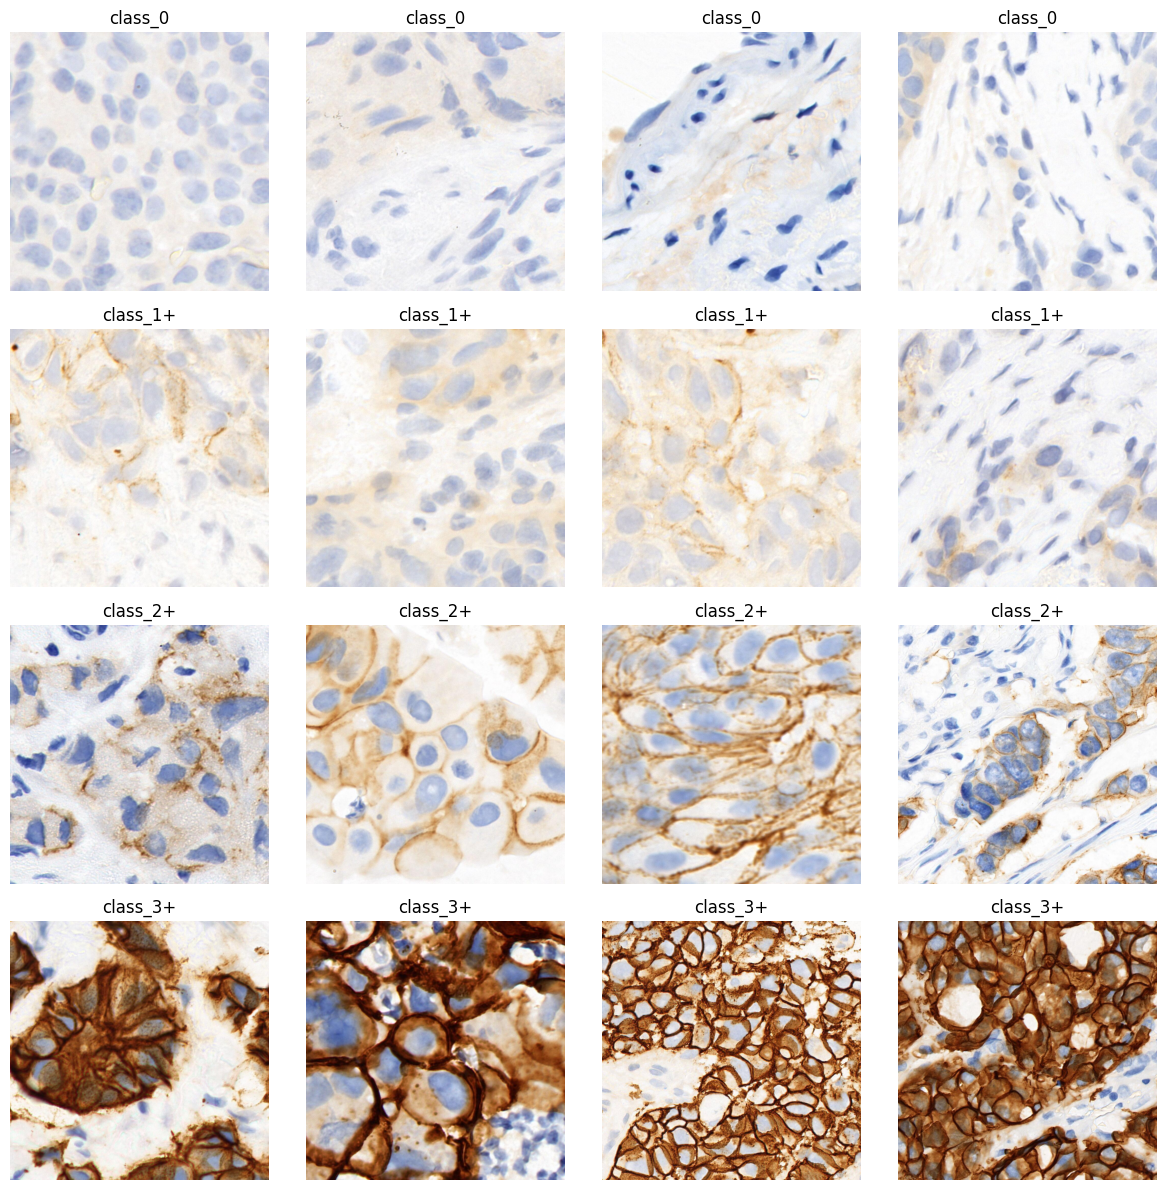

=== Ejemplos de imágenes del conjunto de test por clase ===


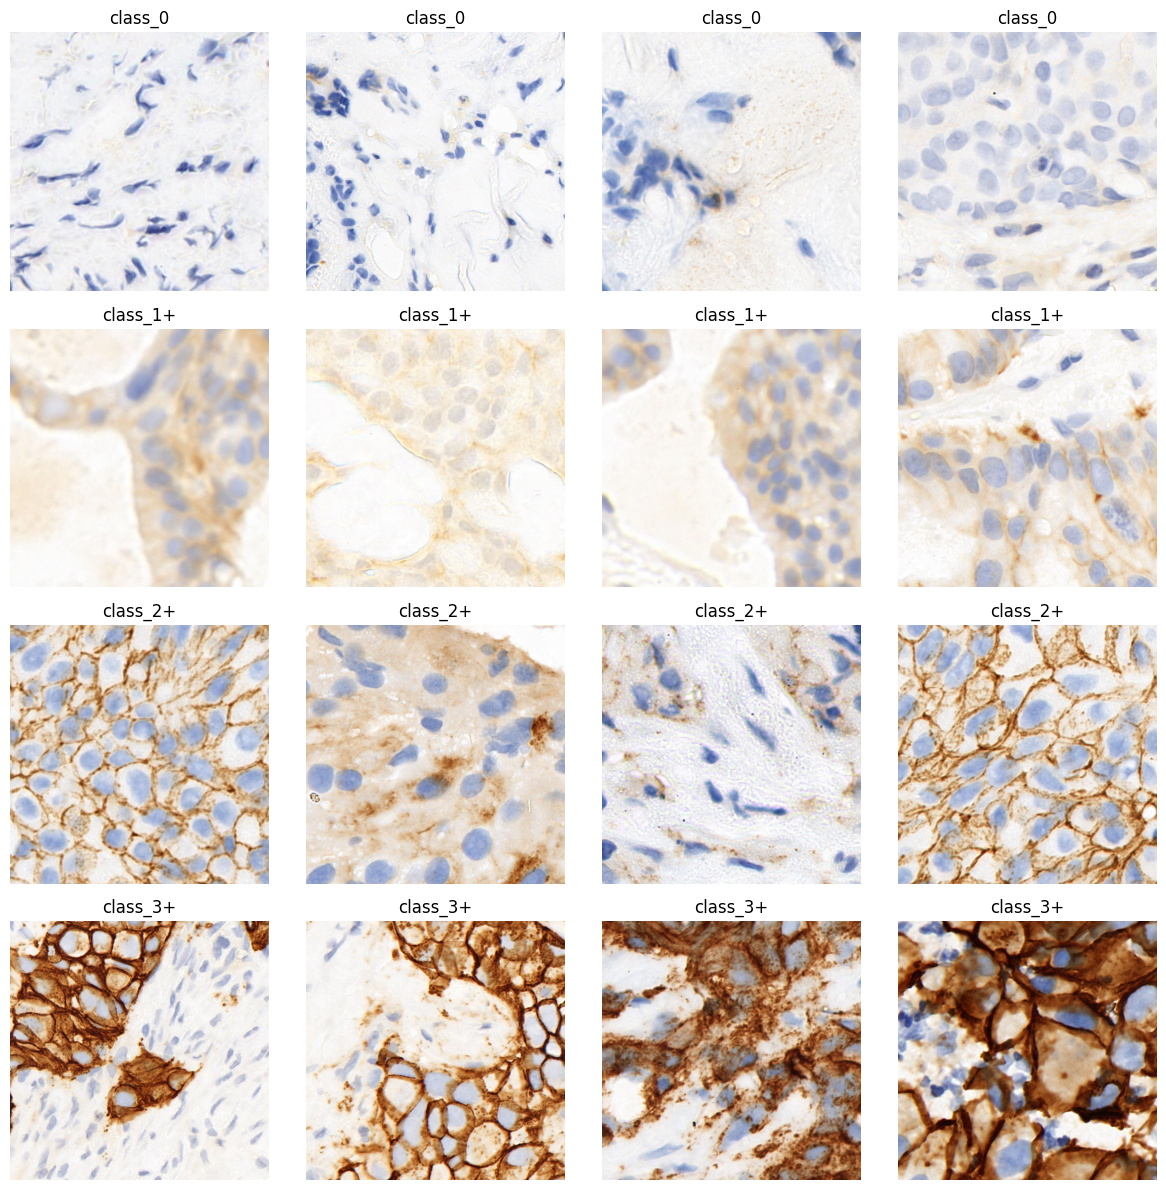

In [3]:
import matplotlib.pyplot as plt
from PIL import Image
import random

def show_images_from_df(df, images_per_class=5, random_seed=42):
    """
    Muestra un número variable de imágenes por clase usando el DataFrame.
    
    Parámetros:
    - df: DataFrame con columnas 'class' y 'file'
    - images_per_class: número de imágenes por clase
    - random_seed: semilla para reproducibilidad
    """

    random.seed(random_seed)

    classes = sorted(df["class"].unique())
    num_classes = len(classes)

    plt.figure(figsize=(images_per_class * 3, num_classes * 3))

    plot_index = 1

    for class_name in classes:
        class_df = df[df["class"] == class_name]

        if len(class_df) == 0:
            continue

        sampled = class_df.sample(
            n=min(images_per_class, len(class_df)),
            random_state=random_seed
        )

        for _, row in sampled.iterrows():
            img = Image.open(row["file"]).convert("RGB")

            plt.subplot(num_classes, images_per_class, plot_index)
            plt.imshow(img)
            plt.title(class_name)
            plt.axis("off")

            plot_index += 1

    plt.tight_layout()
    plt.show()

print("=== Ejemplos de imágenes del conjunto de entrenamiento por clase ===")
train_df = pd.read_pickle("/workspace/data/her2_features_dataset_train.pkl")
show_images_from_df(train_df, images_per_class=4)

print("=== Ejemplos de imágenes del conjunto de test por clase ===")
test_df = pd.read_pickle("/workspace/data/her2_features_dataset_test.pkl")
show_images_from_df(test_df, images_per_class=4)

In [7]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import numpy as np
import joblib

def train_ml_model(df):
    # ----------------------
    # 1. Definir variables
    # ----------------------
    feature_cols = [
        "mean_r",
        "mean_g",
        "mean_b",
        "mean_intensity",
        "variance",
        "dark_ratio"
    ]

    X = df[feature_cols].values
    y = df["class"].values

    # Codificar etiquetas
    le = LabelEncoder()
    y_encoded = le.fit_transform(y)

    # ----------------------
    # 2. Split estratificado
    # ----------------------
    X_train, X_test, y_train, y_test = train_test_split(
        X, y_encoded,
        test_size=0.1,
        stratify=y_encoded,
        random_state=42
    )

    # ----------------------
    # 3. Modelo
    # ----------------------
    model = RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    # ----------------------
    # 4. Evaluación
    # ----------------------
    y_pred = model.predict(X_test)

    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("\nClassification Report:\n")
    print(classification_report(y_test, y_pred, target_names=le.classes_))
    print("\nConfusion Matrix:\n")
    print(confusion_matrix(y_test, y_pred))

    # ----------------------
    # 5. Validación cruzada
    # ----------------------
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    # print(sklearn.metrics.get_scorer_names())
    cv_scores = cross_val_score(model, X, y_encoded, cv=cv, scoring="f1_macro")

    print("\n Cross-validation f1-score:")
    print("\nMean:", np.mean(cv_scores))
    print("Std:", np.std(cv_scores))

    # ----------------------
    # 6. Guardar modelo
    # ----------------------
    joblib.dump(model, "/workspace/models/her2_rf_model.pkl")
    joblib.dump(le, "/workspace/models/label_encoder.pkl")

    return model, le

train_df = pd.read_pickle("/workspace/data/her2_features_dataset_train.pkl")
model, label_encoder = train_ml_model(train_df)

feature_cols = [
        "mean_r",
        "mean_g",
        "mean_b",
        "mean_intensity",
        "variance",
        "dark_ratio"
    ]
importances = model.feature_importances_
print("\nFeature Importances:")
for name, importance in zip(feature_cols, importances):
    print(name, importance)

Accuracy: 0.9

Classification Report:

              precision    recall  f1-score   support

     class_0       0.88      0.91      0.90       313
    class_1+       0.81      0.79      0.80       184
    class_2+       0.83      0.73      0.78        52
    class_3+       1.00      1.00      1.00       261

    accuracy                           0.90       810
   macro avg       0.88      0.86      0.87       810
weighted avg       0.90      0.90      0.90       810


Confusion Matrix:

[[286  24   3   0]
 [ 35 145   4   0]
 [  5   9  38   0]
 [  0   0   1 260]]

 Cross-validation f1-score:

Mean: 0.8673538359308764
Std: 0.008038353979767793

Feature Importances:
mean_r 0.0815818527629108
mean_g 0.1152555829129131
mean_b 0.23721204553843964
mean_intensity 0.09882831575069627
variance 0.2705832732559255
dark_ratio 0.1965389297791145


In [11]:
import joblib
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)
from sklearn.preprocessing import label_binarize

def evaluate_on_test_set(df_test):

    model = joblib.load("/workspace/models/her2_rf_model.pkl")
    le = joblib.load("/workspace/models/label_encoder.pkl")

    feature_cols = [
        "mean_r",
        "mean_g",
        "mean_b",
        "mean_intensity",
        "variance",
        "dark_ratio"
    ]

    # ----------------------
    # Preparar datos
    # ----------------------
    X_test = df_test[feature_cols].values
    y_true = df_test["class"].values
    y_true_encoded = le.transform(y_true)

    # ----------------------
    # Predicciones
    # ----------------------
    y_pred_encoded = model.predict(X_test)
    y_pred = le.inverse_transform(y_pred_encoded)

    y_proba = model.predict_proba(X_test)

    # ----------------------
    # Métricas básicas
    # ----------------------
    acc = accuracy_score(y_true_encoded, y_pred_encoded)

    print("Accuracy:", acc)
    print("\nClassification Report:\n")
    print(classification_report(
        y_true_encoded,
        y_pred_encoded,
        target_names=le.classes_
    ))

    print("\nConfusion Matrix:\n")
    print(confusion_matrix(y_true_encoded, y_pred_encoded))

    # ----------------------
    # ROC-AUC multiclase
    # ----------------------
    try:
        auc = roc_auc_score(
            y_true_encoded,
            y_proba,
            multi_class="ovr"
        )
        print("\nROC-AUC (OvR):", auc)
    except:
        print("\nROC-AUC no calculable.")

     # ----------------------
    # AUPRC multiclase (OvR)
    # ----------------------
    y_true_bin = label_binarize(y_true_encoded, classes=np.arange(len(le.classes_)))

    auprc_macro = average_precision_score(
        y_true_bin,
        y_proba,
        average="macro"
    )

    auprc_weighted = average_precision_score(
        y_true_bin,
        y_proba,
        average="weighted"
    )

    print("AUPRC (macro):", auprc_macro)
    print("AUPRC (weighted):", auprc_weighted)

test_df = pd.read_pickle("/workspace/data/her2_features_dataset_test.pkl")
evaluate_on_test_set(test_df)

Accuracy: 0.9041689225771521

Classification Report:

              precision    recall  f1-score   support

     class_0       0.93      0.86      0.90       658
    class_1+       0.73      0.82      0.77       316
    class_2+       0.73      0.81      0.77       111
    class_3+       0.99      0.99      0.99       762

    accuracy                           0.90      1847
   macro avg       0.84      0.87      0.86      1847
weighted avg       0.91      0.90      0.91      1847


Confusion Matrix:

[[567  82   9   0]
 [ 36 259  19   2]
 [  4  14  90   3]
 [  0   2   6 754]]

ROC-AUC (OvR): 0.9862283798242664
AUPRC (macro): 0.9373258479076201
AUPRC (weighted): 0.961824196633281


In [14]:
from PIL import Image
import numpy as np
import joblib

def extract_features_from_image(image_path):
    img = Image.open(image_path).convert("RGB")
    arr = np.array(img)

    mean_r = np.mean(arr[:, :, 0])
    mean_g = np.mean(arr[:, :, 1])
    mean_b = np.mean(arr[:, :, 2])
    mean_intensity = np.mean(arr)
    variance = np.var(arr)
    dark_ratio = np.sum(arr.mean(axis=2) < 100) / (arr.shape[0] * arr.shape[1])

    return np.array([[mean_r, mean_g, mean_b,
                      mean_intensity, variance, dark_ratio]])


def predict_image(image_path):
    model = joblib.load("/workspace/models/her2_rf_model.pkl")
    le = joblib.load("/workspace/models/label_encoder.pkl")

    features = extract_features_from_image(image_path)
    prediction = model.predict(features)

    return le.inverse_transform(prediction)[0]


print(predict_image(f"{test_folder}/class_0/her2-0-score_test_1192.png"))

class_0
